# Figure 3 Supplement 2: The commit hazard rules out a constant bound

When does a subject commit, given where the pigeon is? The model-free **commit
hazard** is P(commit at step j | |x_j|, not committed before step j), with the
commit step placed at `RT − 2` (NDT = 1 step, the most common fitted value) for
real and simulated trials alike (`pigeon.stopping.get_commit_hazard_table`).

A constant bound commits whenever |x| exceeds it, so the hazard at a given |x|
should be highest right away. The data show the opposite at the first step:
even when the pigeon is already far from center after one step, subjects
rarely commit. The fitted collapsing (knee-form) bound reproduces this with a
bound that starts high; a constant bound does not, and neither does a constant
bound with a guess rate that changes over the trial (the "more guessing early"
alternative).

- **A — hazard vs. step** for positions far from center (|x| ≥ 0.3).
- **B — hazard vs. |x| at the first step.**

Columns: OL low-SNR blocks 1–3 (no-penalty, coin-penalty and step-penalty
conditions), as in the other Figure 3 supplements. Data: black, with 95%
bootstrap intervals over subjects. Models (each subject simulated `SIM_REPS`
times over their own trials from that model's fit): the main model (knee form,
dashed blue), a constant bound (fit variant `flat`, gray dashed), and a constant
bound with a guess-rate time course (`flat_guess_tc`, gray dotted). All
subject-blocks are included.

Replaces the old Figure03S03 (fixed-bound simulations of incongruence and
premature crossings; archived in `notebooks/archive/`): with the stopping
model, those statistics are reproduced with or without sensory noise, so they
no longer discriminate between decision rules.

In [1]:
import sys
sys.path.insert(0, '..')

from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd

from pigeon.pathDefaults import FIGURES_DIR
from pigeon.plotting import FONT_RC, add_panel_label
from pigeon.stopping import get_commit_hazard_table, get_stopping_model_trials, simulate_stopping_data_table

PROCESSED = Path('../data/processed')

In [2]:
SIM_REPS = 5
SIM_SEED = 5
BOOT_REPS = 1000
BOOT_SEED = 1
HAZARD_NDT = 1
BLOCKS = ['B1', 'B2', 'B3']
BLOCK_TITLES = {'B1': 'No penalty', 'B2': 'Coin penalty', 'B3': 'Step penalty'}
MODELS = {'knee (main)': 'main', 'constant bound': 'flat', 'constant bound + guess time course': 'flat_guess_tc'}
FAR_X = 0.3
STEP_BINS = [1, 2, 3, 4, 6, 9, 13]          # left edges; last bin 13+ is not shown (sparse)
X_BINS = [0, 0.1, 0.2, 0.3, 0.45, 0.75]

trials = get_stopping_model_trials('OL', [1, 2, 3, 4, 5, 6])
trials = trials[trials.condition.isin(BLOCKS)]
sims = {}
for label, variant in MODELS.items():
    f = pd.read_pickle(PROCESSED / f'stopping_fits_{variant}.pkl')
    sims[label] = simulate_stopping_data_table(trials, f[f.task == 'OL'], group_col='condition', num_reps=SIM_REPS,
                                               rng=np.random.default_rng(SIM_SEED))
haz = {'data': get_commit_hazard_table(trials, ndt=HAZARD_NDT)}
haz.update({label: get_commit_hazard_table(s, ndt=HAZARD_NDT) for label, s in sims.items()})
for label, h in haz.items():
    h['step_bin'] = pd.cut(h.step, STEP_BINS, right=False, labels=STEP_BINS[:-1])
    h['x_bin'] = pd.cut(h.abs_x, X_BINS, right=False, labels=X_BINS[:-1])
print(f'{len(trials):,} real trials; hazard rows (step x trial at risk): '
      + ', '.join(f'{k} {len(v):,}' for k, v in haz.items()))

OL: subjects with a good adaptation tau fit, by block: {1: 2, 2: 25, 3: 9, 4: 18, 5: 8, 6: 9}
OL: 42,252 trials in blocks [1, 2, 3, 4, 5, 6]; excluded 3,240 with trial_number < 10, 225 more in the adaptation transient, 364 more with no choice; 60 subjects


14,056 real trials; hazard rows (step x trial at risk): data 49,830, knee (main) 248,292, constant bound 249,830, constant bound + guess time course 246,011


In [3]:
def _pooled(h, by):
    # Pooled hazard per bin (all at-risk steps in the bin, all subjects).
    return h.groupby(by, observed=True).commit.mean()

def _boot_ci(h, by, rng):
    # 95% interval from resampling subjects (with replacement).
    sums = h.groupby(['subject_index', by], observed=True).commit.agg(['sum', 'size']).unstack(by, fill_value=0)
    subj = sums.index.to_numpy()
    k, n = sums['sum'].to_numpy(float), sums['size'].to_numpy(float)
    idx = rng.integers(0, len(subj), (BOOT_REPS, len(subj)))
    boot = k[idx].sum(axis=1) / np.maximum(n[idx].sum(axis=1), 1)
    lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
    return pd.DataFrame({'lo': lo, 'hi': hi}, index=sums['sum'].columns)

rng = np.random.default_rng(BOOT_SEED)
panel_a, panel_b = {}, {}
for b in BLOCKS:
    far = {k: h[(h.condition == b) & (h.abs_x >= FAR_X) & h.step_bin.notna()] for k, h in haz.items()}
    first = {k: h[(h.condition == b) & (h.step == 1) & h.x_bin.notna()] for k, h in haz.items()}
    panel_a[b] = ({k: _pooled(v, 'step_bin') for k, v in far.items()}, _boot_ci(far['data'], 'step_bin', rng),
                  far['data'].groupby('step_bin', observed=True).size())
    panel_b[b] = ({k: _pooled(v, 'x_bin') for k, v in first.items()}, _boot_ci(first['data'], 'x_bin', rng),
                  first['data'].groupby('x_bin', observed=True).size())
    print(f'== {b}: hazard vs. step at |x| >= {FAR_X} (data n at risk per bin: {panel_a[b][2].to_dict()})')
    print(pd.DataFrame(panel_a[b][0]).T.round(3).to_string())
    print(f'   hazard vs. |x| at step 1 (data n per bin: {panel_b[b][2].to_dict()})')
    print(pd.DataFrame(panel_b[b][0]).T.round(3).to_string())

== B1: hazard vs. step at |x| >= 0.3 (data n at risk per bin: {1: 297, 2: 849, 3: 772, 4: 903, 6: 542, 9: 238})
step_bin                                1      2      3      4      6      9
data                                0.256  0.527  0.585  0.553  0.511  0.412
knee (main)                         0.340  0.524  0.564  0.569  0.499  0.469
constant bound                      0.454  0.563  0.551  0.522  0.459  0.415
constant bound + guess time course  0.449  0.552  0.525  0.523  0.467  0.412
   hazard vs. |x| at step 1 (data n per bin: {0.0: 2571, 0.1: 1752, 0.2: 890, 0.3: 277, 0.45: 20})
x_bin                                0.00   0.10   0.20   0.30   0.45
data                                0.166  0.219  0.255  0.256  0.250
knee (main)                         0.205  0.244  0.283  0.337  0.383
constant bound                      0.232  0.290  0.365  0.450  0.514
constant bound + guess time course  0.232  0.282  0.360  0.445  0.509
== B2: hazard vs. step at |x| >= 0.3 (data n at risk p

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


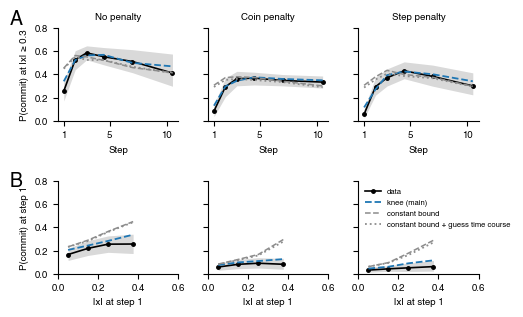

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure03_S02.pdf (+ .png)


In [4]:
CM = 1 / 2.54
FS = 7
plt.rcParams.update({'font.size': FS, 'axes.labelsize': FS, 'axes.titlesize': FS, **FONT_RC})
MODEL = 'tab:blue'
STYLE = {'knee (main)': dict(color=MODEL, ls='--', lw=1.3),
         'constant bound': dict(color='0.55', ls='--', lw=1.1),
         'constant bound + guess time course': dict(color='0.55', ls=':', lw=1.3)}
MIN_DATA_N = 30   # bins with fewer real at-risk steps are not drawn

def _draw(ax, curves, ci, n, centers):
    ok = (n.reindex(curves['data'].index).fillna(0) >= MIN_DATA_N).to_numpy()
    x = np.asarray(centers)[ok]
    d = curves['data'][ok]
    ax.fill_between(x, ci['lo'].reindex(d.index), ci['hi'].reindex(d.index), color='k', alpha=0.15, lw=0)
    ax.plot(x, d, 'k-', marker='o', ms=2.5, lw=1.2, label='data')
    for k, st in STYLE.items():
        ax.plot(x, curves[k].reindex(d.index), label=k, **st)

step_centers = {s: (s + e - 1) / 2 for s, e in zip(STEP_BINS[:-1], STEP_BINS[1:])}
x_centers = {s: (s + e) / 2 for s, e in zip(X_BINS[:-1], X_BINS[1:])}

fig = plt.figure(figsize=(12 * CM, 8 * CM))
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.65, wspace=0.25, left=0.1, right=0.99, bottom=0.12, top=0.9)
for bi, b in enumerate(BLOCKS):
    ax = fig.add_subplot(gs[0, bi])
    curves, ci, n = panel_a[b]
    _draw(ax, curves, ci, n, [step_centers[s] for s in curves['data'].index])
    ax.set_title(BLOCK_TITLES[b])
    ax.set_xlabel('Step')
    ax.set_xlim(0.5, 11)
    ax.set_xticks([1, 5, 10])
    ax.set_ylim(0, 0.8)
    if bi == 0:
        ax.set_ylabel(f'P(commit) at |x| ≥ {FAR_X}')
        add_panel_label(ax, 'A', dx=-0.4, dy=1.2)
    else:
        ax.set_yticklabels([])
    ax.spines[['top', 'right']].set_visible(False)

    ax = fig.add_subplot(gs[1, bi])
    curves, ci, n = panel_b[b]
    _draw(ax, curves, ci, n, [x_centers[s] for s in curves['data'].index])
    ax.set_xlabel('|x| at step 1')
    ax.set_xlim(0, 0.6)
    ax.set_ylim(0, 0.8)
    if bi == 0:
        ax.set_ylabel('P(commit) at step 1')
        add_panel_label(ax, 'B', dx=-0.4, dy=1.1)
    else:
        ax.set_yticklabels([])
    if bi == 2:
        ax.legend(fontsize=5.5, frameon=False, loc='upper left')
    ax.spines[['top', 'right']].set_visible(False)

out = FIGURES_DIR / 'Figure03_S02.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
fig.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')

## Interpretation

(Filled in after review.)